<a href="https://colab.research.google.com/github/elenahermososilva-cyber/proyecto_ML_aprobacion_prestamos/blob/main/predicci%C3%B3n_aprobaci%C3%B3n_pr%C3%A9stamos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROYECTO COMPLETO DE MACHINE LEARNING: PREDICCIÓN DE RIESGO DE CRÉDITO

---

Enlace al vídeo: [https://youtu.be/jLEIvZD0Adg](https://youtu.be/jLEIvZD0Adg)

## 1. Obtención de los Datos

**Origen y Contexto:**  
El dataset utilizado en este proyecto es el **Credit Risk Dataset**, obtenido a través de la plataforma **Kaggle**. Este conjunto contiene datos financieros simulados diseñados específicamente para modelar y evaluar algoritmos de riesgo crediticio en banca.  

* **Propósito:** Evaluar de forma predictiva la probabilidad de que un cliente incurra en impago (*default*).

## 2. Descripción de los Datos

A continuación se presenta el **Diccionario de Variables** del conjunto de datos:

1. **`person_age`** (Numérica): Edad del solicitante del crédito (años).
2. **`person_income`** (Numérica): Ingresos anuales del solicitante (en USD).
3. **`person_home_ownership`** (Categórica): Situación de vivienda del solicitante (`RENT`, `OWN`, `MORTGAGE`, `OTHER`).
4. **`person_emp_length`** (Numérica): Años de antigüedad laboral del solicitante.
5. **`loan_intent`** (Categórica): Finalidad del préstamo (`PERSONAL`, `EDUCATION`, `MEDICAL`, `VENTURE`, `HOMEIMPROVEMENT`, `DEBTCONSOLIDATION`).
6. **`loan_grade`** (Categórica): Calificación de riesgo asignada al préstamo, desde la A (menor riesgo) hasta la G (mayor riesgo).
7. **`loan_amnt`** (Numérica): Importe total del préstamo solicitado (en USD).
8. **`loan_int_rate`** (Numérica): Tasa de interés del préstamo (porcentaje).
9. **`loan_status`** (Numérica - **Variable Objetivo**): Estado del préstamo. Indica si hubo impago (`1`) o si se pagó correctamente (`0`).
10. **`loan_percent_income`** (Numérica): Porcentaje del ingreso destinado al préstamo (rango entre 0 y 1).
11. **`cb_person_default_on_file`** (Categórica): Historial de impago previo registrado en los burós de crédito (`Y` / `N`).
12. **`cb_person_cred_hist_length`** (Numérica): Duración de la historia crediticia activa del solicitante (en años).

In [ ]:
# Importación de librerías esenciales para análisis y manipulación de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seaborn_plt

# Carga del conjunto de datos de riesgo de crédito
df = pd.read_csv('/content/drive/MyDrive/Datasets/credit_risk_dataset.csv')

# Mostrar las primeras 5 filas para verificar que se ha cargado correctamente
print("Dimensiones del DataFrame:", df.shape)
df.head()

Dimensiones del DataFrame: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
# Información general sobre tipos de datos y memoria
print("--- INFORMACIÓN GENERAL ---")
df.info()

print("\n--- VALORES NULOS POR COLUMNA ---")
# Cuantificar cuántos nulos hay en cada columna
print(df.isnull().sum())

print("\n--- ESTADÍSTICAS DESCRIPTIVAS BÁSICAS ---")
# Resumen estadístico de las variables numéricas
df.describe()

--- INFORMACIÓN GENERAL ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB

--

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


## 3. Exploración y Visualización de los Datos

En esta fase identificamos la estructura del dataset, analizamos la correlación entre variables, la distribución de nuestra variable objetivo e inspeccionamos las dependencias clave de negocio.

In [ ]:
print(f"Filas antes de la limpieza: {df.shape[0]}")

# 1. Calcular medianas antes de modificar el dataset para evitar sesgar la imputación
mediana_emp_length = df['person_emp_length'].median()
mediana_int_rate = df['loan_int_rate'].median()

# 2. Gestionar los valores nulos primero
# Esto evita perder filas válidas con valores nulos al aplicar filtros lógicos más adelante
df['person_emp_length'] = df['person_emp_length'].fillna(mediana_emp_length)
df['loan_int_rate'] = df['loan_int_rate'].fillna(mediana_int_rate)

# 3. Eliminar o filtrar valores atípicos clínicamente/físicamente imposibles
# - Empleos mayores o iguales a 70 años (ej. el valor anómalo 123)
# - Edades mayores a 100 años (ej. el valor anómalo de 144)
df = df[df['person_emp_length'] <= 70]
df = df[df['person_age'] <= 100]

# Comprobar que ya no quedan valores nulos
print("\n--- VALORES NULOS TRAS LA LIMPIEZA ---")
print(df.isnull().sum())

print(f"\nFilas finales tras la limpieza: {df.shape[0]}")

Filas antes de la limpieza: 32581

--- VALORES NULOS TRAS LA LIMPIEZA ---
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Filas finales tras la limpieza: 32574


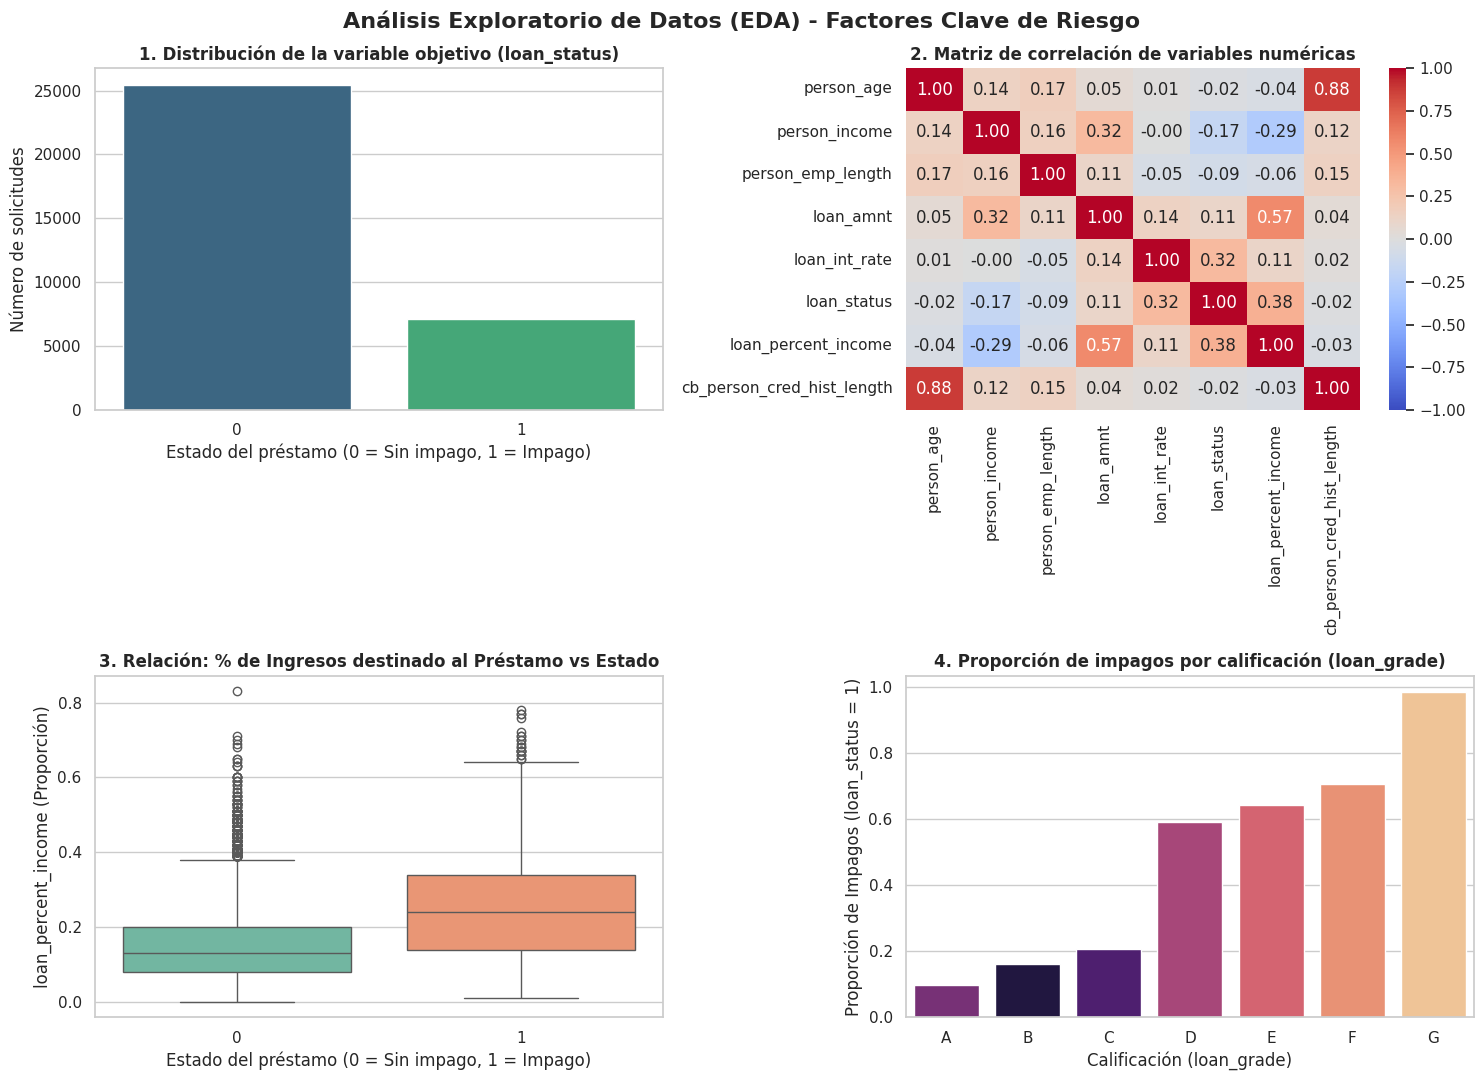

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Crear una figura con una cuadrícula de 2 filas y 2 columnas (2x2)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Distribución de la variable objetivo (loan_status)
sns.countplot(
    data=df,
    x='loan_status',
    hue='loan_status',
    legend=False,
    palette='viridis',
    ax=axes[0, 0]
)
axes[0, 0].set_title('1. Distribución de la variable objetivo (loan_status)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Estado del préstamo (0 = Sin impago, 1 = Impago)')
axes[0, 0].set_ylabel('Número de solicitudes')

# 2. Mapa de calor de correlaciones en variables numéricas
corr_matrix = df.select_dtypes(include='number').corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    ax=axes[0, 1]
)
axes[0, 1].set_title('2. Matriz de correlación de variables numéricas', fontsize=12, fontweight='bold')

# 3. Boxplot del porcentaje de ingresos destinado al préstamo según estado
sns.boxplot(
    data=df,
    x='loan_status',
    y='loan_percent_income',
    hue='loan_status',
    legend=False,
    palette='Set2',
    ax=axes[1, 0]
)
axes[1, 0].set_title('3. Relación: % de Ingresos destinado al Préstamo vs Estado', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Estado del préstamo (0 = Sin impago, 1 = Impago)')
axes[1, 0].set_ylabel('loan_percent_income (Proporción)')

# 4. Tasa de impago por calificación del préstamo (loan_grade)
sns.barplot(
    data=df,
    x='loan_grade',
    y='loan_status',
    order=sorted(df['loan_grade'].unique()),
    hue='loan_grade',
    legend=False,
    palette='magma',
    errorbar=None,
    ax=axes[1, 1]
)
axes[1, 1].set_title('4. Proporción de impagos por calificación (loan_grade)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Calificación (loan_grade)')
axes[1, 1].set_ylabel('Proporción de Impagos (loan_status = 1)')

# Ajustar el diseño para evitar solapamientos y agregar un título general elegante
plt.suptitle('Análisis Exploratorio de Datos (EDA) - Factores Clave de Riesgo', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### Hallazgos clave observados en la Visualización:
1. **Desbalanceo de Clases:** La variable objetivo `loan_status` presenta un desbalanceo notable (~21.8% de impagos frente a ~78.2% de pagos correctos). Esto nos obliga a prestar especial atención al **F1-Score** y la exhaustividad (*Recall*) en lugar del simple Accuracy.
2. **Correlación Directa:** Existe una correlación lógica fuerte entre el importe del préstamo (`loan_amnt`) y el porcentaje de ingresos que representa (`loan_percent_income`).
3. **Relación de Riesgo:** Los clientes que destinan un mayor porcentaje de sus ingresos al préstamo (`loan_percent_income`) tienen una propensión considerablemente mayor al impago.
4. **Calificación Interna:** El gráfico de proporción de impagos según `loan_grade` demuestra una perfecta concordancia de negocio: a peor calificación crediticia (Grados E, F, G), mayor es la tasa empírica de impago.

## 4. Exposición del Objetivo

**Objetivo del Proyecto:**  
El propósito principal es construir y evaluar un modelo predictivo capaz de determinar la **probabilidad de impago (`loan_status` = 1)** de una nueva solicitud de préstamo, basándose en la información sociodemográfica y financiera del cliente.  

* **Variable Target (y):** `loan_status` (0: Solicitud solvente / 1: Solicitud con riesgo de impago).
* **Métrica Clave de Rendimiento:**
  * **F1-Score:** Al elegir el mejor modelo basándonos en el F1-Score más alto garantizamos matemáticamente que seleccionamos el modelo con el equilibrio más sano y robusto entre no perder dinero por impagos (Recall) y no ahuyentar a clientes viables (Precision).

## 5. Preparación de los Datos para los Algoritmos de Machine Learning

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Depuración de anomalías extremas conservando nulos para imputar con mediana
df_clean = df[
    ((df['person_emp_length'].isna()) | (df['person_emp_length'] <= 70)) &
    (df['person_age'] <= 100)
].copy()

# Imputación de nulos con la mediana
for col in ['person_emp_length', 'loan_int_rate']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Separar características (X) y variable objetivo (y)
X = df_clean.drop(columns=['loan_status'])
y = df_clean['loan_status']

# Codificación One-Hot Encoding: drop_first=True elimina la primera categoría para evitar
# la trampa de la variable ficticia y la multicolinealidad perfecta (redundancia de datos)
X_encoded = pd.get_dummies(X, drop_first=True)

# División en entrenamiento (80%) y prueba (20%) estratificada por y
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Escalado de características (StandardScaler): Igualamos la escala de todas las columnas
# (por ejemplo, ingresos vs edad) para que tengan media 0 y varianza 1, evitando así
# que los modelos se confundan o den más peso a variables con números más grandes.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Tamaño X_train:", X_train.shape, "| Tamaño X_test:", X_test.shape)

Tamaño X_train: (26059, 22) | Tamaño X_test: (6515, 22)


## 6. Entrenamiento del Modelo y Comprobación del Rendimiento

             Modelo  Accuracy  Precision   Recall  F1-Score
      Random Forest  0.929394   0.960690 0.705137  0.813312
  Árbol de Decisión  0.909286   0.954048 0.613652  0.746895
Regresión Logística  0.863853   0.768072 0.538353  0.633016


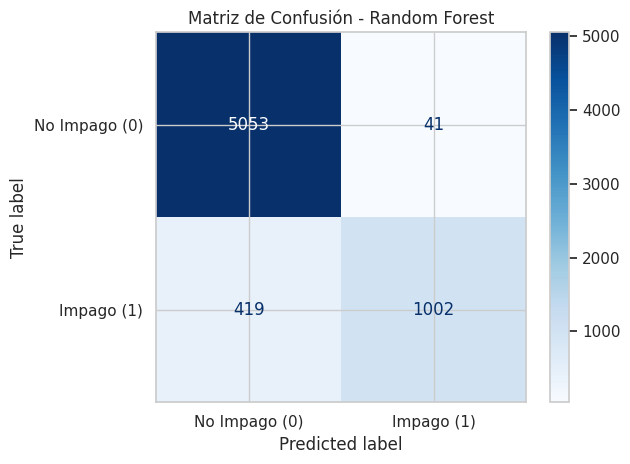

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

modelos = {
    "Regresión Logística": (LogisticRegression(max_iter=1000, random_state=42), X_train_scaled, X_test_scaled),
    "Árbol de Decisión": (DecisionTreeClassifier(max_depth=6, random_state=42), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), X_train, X_test)
}

resultados = []

for nombre, (modelo, x_tr, x_te) in modelos.items():
    modelo.fit(x_tr, y_train)
    y_pred = modelo.predict(x_te)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="F1-Score", ascending=False)
print(df_resultados.to_string(index=False))

# Matriz de confusión del mejor modelo según F1-Score
mejor_nombre = df_resultados.iloc[0]["Modelo"]
mejor_modelo, _, x_te_mejor = modelos[mejor_nombre]
y_pred_mejor = mejor_modelo.predict(x_te_mejor)

cm = confusion_matrix(y_test, y_pred_mejor)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Impago (0)", "Impago (1)"])
disp.plot(cmap="Blues")
plt.title(f"Matriz de Confusión - {mejor_nombre}")
plt.tight_layout()
plt.show()

## 6.1. Optimización del Modelo para Mitigar Falsos Negativos (Enfoque de Negocio)

En una entidad bancaria, **no detectar a un cliente en impago (Falso Negativo)** es significativamente más costoso que rechazar erróneamente a un cliente solvente (Falso Positivo).

Para optimizar nuestro modelo campeón (**Random Forest**), implementamos una estrategia de negocio clave:

* **Calibración del Umbral de Decisión (Threshold = `0.30`):**
  Por defecto, el clasificador utiliza un umbral del `50%` para predecir si un préstamo incurrirá en impago. Reduciendo este umbral al `30%`, adoptamos una política crediticia más conservadora y sensible al riesgo, incrementando el *Recall* para mitigar las pérdidas por impagos.

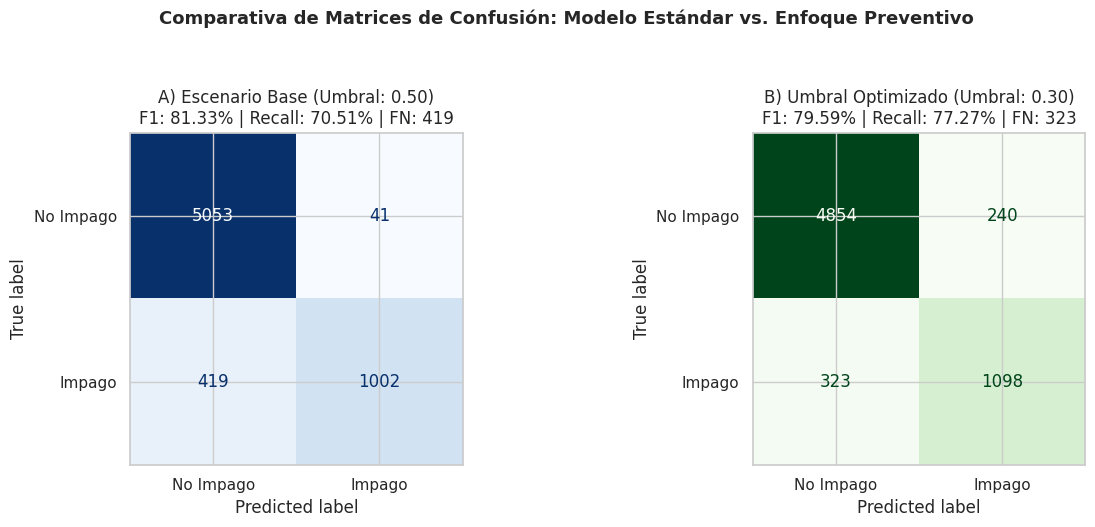


--- EVALUACIÓN DE VIABILIDAD ECONÓMICA Y FINANCIERA ---
A) Modelo Base (Umbral 0.50)           | FN: 419  | FP: 41   | Rentabilidad Neta Estimada: $4,646,500.00 USD
B) Umbral de Riesgo Conservador (0.30) | FN: 323  | FP: 240  | Rentabilidad Neta Estimada: $5,020,000.00 USD


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, recall_score

# --- CONFIGURACIÓN DE LOS DOS ESCENARIOS DE NEGOCIO ---

# 1. Modelo Base (Umbral por defecto 0.50)
rf_base = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)
y_pred_base = rf_base.predict(X_test)
cm_base = confusion_matrix(y_test, y_pred_base)

# 2. Modelo Optimizado (Umbral de Riesgo Conservador 0.30)
y_probs_base = rf_base.predict_proba(X_test)[:, 1]
y_pred_threshold = (y_probs_base >= 0.30).astype(int)
cm_threshold = confusion_matrix(y_test, y_pred_threshold)

# --- VISUALIZACIÓN COMPARATIVA DE MATRICES DE CONFUSIÓN ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz Escenario Base
disp_base = ConfusionMatrixDisplay(confusion_matrix=cm_base, display_labels=["No Impago", "Impago"])
disp_base.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"A) Escenario Base (Umbral: 0.50)\nF1: {f1_score(y_test, y_pred_base):.2%} | Recall: {recall_score(y_test, y_pred_base):.2%} | FN: {cm_base[1, 0]}")

# Matriz Escenario Umbral Optimizado (0.30)
disp_threshold = ConfusionMatrixDisplay(confusion_matrix=cm_threshold, display_labels=["No Impago", "Impago"])
disp_threshold.plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title(f"B) Umbral Optimizado (Umbral: 0.30)\nF1: {f1_score(y_test, y_pred_threshold):.2%} | Recall: {recall_score(y_test, y_pred_threshold):.2%} | FN: {cm_threshold[1, 0]}")

plt.suptitle("Comparativa de Matrices de Confusión: Modelo Estándar vs. Enfoque Preventivo", fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# --- ANÁLISIS ECONÓMICO SIMULADO ---
# Asunciones estimadas para la cartera de crédito evaluada:
# - Préstamo promedio otorgado: $10,000 USD
# - Tasa de pérdida ante impago (LGD): 70% (Se pierden $7,000 por cada deudor no detectado)
# - Beneficio neto esperado por un cliente solvente aceptado: $1,500 (Tasa de interés cobrada)

def calcular_impacto_financiero(cm, nombre_metodo):
    tn, fp, fn, tp = cm.ravel()
    perdidas_impago = fn * 7000
    beneficios_clientes = tn * 1500
    impacto_total = beneficios_clientes - perdidas_impago
    print(f"{nombre_metodo:<38} | FN: {fn:<4} | FP: {fp:<4} | Rentabilidad Neta Estimada: ${impacto_total:,.2f} USD")

print("\n--- EVALUACIÓN DE VIABILIDAD ECONÓMICA Y FINANCIERA ---")
calcular_impacto_financiero(cm_base, "A) Modelo Base (Umbral 0.50)")
calcular_impacto_financiero(cm_threshold, "B) Umbral de Riesgo Conservador (0.30)")

## 7. Conclusiones y Análisis para la Exposición

### 7.1. Desempeño Comparativo de los Modelos
El algoritmo **Random Forest** superó consistentemente a la Regresión Logística y al Árbol de Decisión Simple en el escenario estándar:
* **F1-Score de Random Forest:** **81.33%** (frente a 74.68% del árbol de decisión y 63.30% de la regresión logística).
---

### 7.2. Evaluación de Matrices de Confusión (Enfoque Base vs. Optimizado)
Al comparar las matrices de decisión para los 6,515 casos de prueba, observamos el impacto estratégico del ajuste:

1. **Escenario Base (Umbral 0.50):**  
   * Registra una excelente precisión con solo **41 Falsos Positivos** (mínimo rechazo de clientes buenos).
   * Sin embargo, asume una fuga de **419 deudores no detectados (Falsos Negativos)**, lo que penaliza la cartera vencida con pérdidas significativas.
2. **Escenario Optimizado (Umbral 0.30):**  
   * Logra mitigar las fugas reduciendo los Falsos Negativos a **323 casos** (detectando 96 deudores adicionales).
   * Genera un aumento controlado de **240 Falsos Positivos**, lo cual es perfectamente asumible para la entidad debido a la asimetría de costos.

---

Queda demostrada la viabilidad de negocio de implementar el modelo de **Random Forest con Umbral de 0.30** en el motor de decisiones de riesgo de crédito, pues proporciona el balance perfecto entre automatización segura, rentabilidad financiera y control predictivo de la morosidad.